# 00c · Capa de secciones simulada y fraude plantado

> **TODO LO QUE SIGUE ES SIMULADO.** Las secciones tarifarias por línea no son públicas (ver `docs/fuentes.md`).
> Partimos de la forma real de la serie de viajes de cada línea y mes (estacionalidad, tendencia), pero **anonimizamos** líneas y empresas (`L001`, `E001`) y
> **inventamos** cómo se reparten esos viajes entre secciones. El fraude se planta sobre esos identificadores ficticios:
> ningún resultado de acá habla de empresas reales.

**Para qué simular:** para evaluar un detector necesitamos saber la verdad. Con datos reales no la tenemos; con datos simulados
sabemos exactamente qué líneas "hacen trampa" y desde cuándo, y podemos medir cuánto detecta cada método.

**Cómo se construye** (todo parametrizado en `config.yaml`, semilla fija):
1. **Sección de cada viaje.** La distancia de un viaje se modela como lognormal truncada al largo del recorrido real: en una línea de 8 km nadie viaja 20 km.
   Eso define cuántos viajes caen en cada una de las 5 secciones (0–3, 3–6, 6–12, 12–27, >27 km). Cada línea tiene un "estilo" propio y ruido mensual.
2. **Fraude.** Se eligen empresas completas hasta cubrir ≈10 % de las líneas (la orden vendría de la empresa). Desde enero 2026,
   el 20 % de los viajes de las secciones 1–2 se cobra dos secciones más arriba.
3. **Subsidio.** Una bolsa fija se reparte entre empresas en proporción a su recaudación (regla simplificada, supuesto nuestro).
   Si una empresa recauda más por inflar secciones, se lleva una porción mayor a costa de las demás.

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
sim = pd.read_parquet('../data/processed/sim_secciones.parquet')
sub = pd.read_parquet('../data/processed/sim_subsidio.parquet')
l = sim.drop_duplicates('linea_id')
print(f'{len(sim):,} filas | {len(l)} líneas | {sim.empresa_id.nunique()} empresas')
print(f'Líneas con fraude plantado: {l.verdad_linea_fraude.sum()} ({l.verdad_linea_fraude.mean():.1%}), desde 2026-01')
sim.drop(columns=[c for c in sim if c.startswith('verdad_')]).head()

26,642 filas | 390 líneas | 150 empresas
Líneas con fraude plantado: 35 (9.0%), desde 2026-01


,linea_id,empresa_id,jurisdiccion,grupo,mes,largo_km,dist_centro_km,n_ramales,viajes,v1,v2,v3,v4,v5,tarifa_media,dist_media_abonada,pct_sec_max,recaudacion,viajes_sec_imposible
0,L230,E115,C.A.B.A,NAC-3,2025-02-01,9.086995,0.779819,1.0,730889,340276,280900,109713,0,0,1.083646,3.778797,0.0,792025.25,0
1,L230,E115,C.A.B.A,NAC-3,2025-03-01,9.086995,0.779819,1.0,832741,370465,328140,134136,0,0,1.087555,3.890227,0.0,905651.80,0
2,L230,E115,C.A.B.A,NAC-3,2025-04-01,9.086995,0.779819,1.0,863234,388276,338070,136888,0,0,1.086640,3.864214,0.0,938024.40,0
3,L230,E115,C.A.B.A,NAC-3,2025-05-01,9.086995,0.779819,1.0,845257,372608,335305,137344,0,0,1.088225,3.908729,0.0,919829.60,0
4,L230,E115,C.A.B.A,NAC-3,2025-06-01,9.086995,0.779819,1.0,796343,348782,316744,130817,0,0,1.088798,3.925286,0.0,867056.53,0


Las columnas que empiezan con `verdad_` son la respuesta del examen: los detectores **no** pueden usarlas, solo sirven para evaluarlos en la Fase 4.

## 1. ¿Se ve el fraude en la tarifa media?
Tarifa media = promedio de lo cobrado por viaje (en unidades relativas: sección 1 = 1,00).

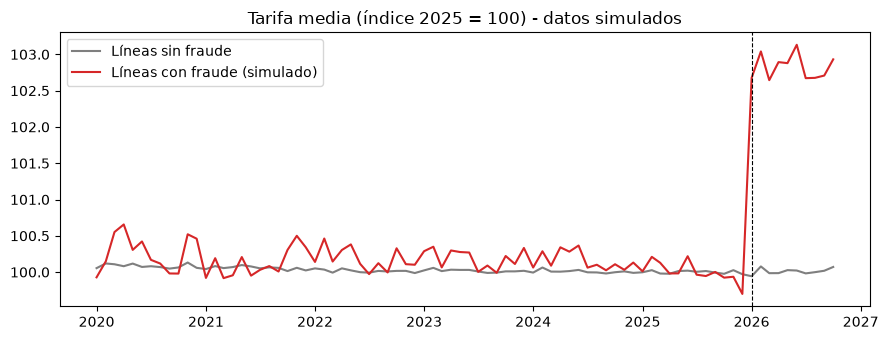

Aumento medio de la tarifa media por el fraude: +2.90%


In [2]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for fr, c, n in [(False, 'tab:gray', 'Líneas sin fraude'), (True, 'tab:red', 'Líneas con fraude (simulado)')]:
    s = sim[sim.verdad_linea_fraude == fr].groupby('mes').tarifa_media.mean()
    ax.plot(s.index, s / s[s.index.year == 2025].mean() * 100, color=c, label=n)
ax.axvline(pd.Timestamp('2026-01-01'), ls='--', color='k', lw=.8); ax.set_title('Tarifa media (índice 2025 = 100) - datos simulados')
ax.legend(); plt.tight_layout(); plt.savefig('../outputs/figures/sim_tarifa_media.png', dpi=150); plt.show()
d = sim[sim.verdad_fraude_activo]
print(f'Aumento medio de la tarifa media por el fraude: {d.tarifa_media.mean() / d.verdad_tarifa_media_cf.mean() - 1:+.2%}')

Con 20 % de los viajes bajos corridos, el efecto sobre el promedio es chico (~3 %) frente al ruido mensual: **es detectable, pero no obvio**.
Ese es justamente el desafío de los métodos de la Fase 3. La magnitud se puede cambiar en `config.yaml` (`fraude.magnitud`) y es la base del análisis de sensibilidad de la Fase 4.

## 2. La pista geográfica
En una línea corta no existen viajes de más de cierta distancia. Si aparecen viajes cobrados en secciones que el recorrido no permite, algo no cierra.

In [3]:
x = sim.assign(imp=sim.viajes_sec_imposible > 0).groupby('verdad_fraude_activo').imp.mean()
print('% de filas línea-mes con viajes en secciones imposibles para el largo de su recorrido:')
print((x * 100).round(1).rename({False: 'sin fraude activo', True: 'con fraude activo'}))

% de filas línea-mes con viajes en secciones imposibles para el largo de su recorrido:
verdad_fraude_activo
sin fraude activo     0.0
con fraude activo    33.9
Name: imp, dtype: float64


Cuidado: esto **no** detecta todos los casos. Una línea larga puede inflar secciones y seguir siendo "plausible" geográficamente. Por eso se necesitan varios métodos.

## 3. Efecto en el reparto de la bolsa
Bolsa fija = 100 por mes. Transferencia = lo que cada empresa recibe menos lo que habría recibido sin fraude.

In [4]:
t = sub[sub.mes >= '2026-01-01'].groupby('empresa_fraude').transferencia.sum()
print('Transferencia acumulada en 2026 (como % de una bolsa mensual):')
print(t.round(2).rename({False: 'empresas sin fraude (en conjunto)', True: 'empresas con fraude (en conjunto)'}))
top = sub[(sub.mes >= '2026-01-01') & sub.empresa_fraude].groupby('empresa_id').transferencia.sum().sort_values(ascending=False)
top.head(8).round(3).to_frame('ganancia acumulada')

Transferencia acumulada en 2026 (como % de una bolsa mensual):
empresa_fraude
empresas sin fraude (en conjunto)   -2.14
empresas con fraude (en conjunto)    2.14
Name: transferencia, dtype: float64


,ganancia acumulada
empresa_id,
E137,0.400
E085,0.250
E111,0.242
E075,0.209
E107,0.182
E132,0.161
E061,0.146
E109,0.119


Lo que una empresa gana, otras lo pierden: la bolsa es fija. Por eso el perjuicio al Estado no es "más plata" sino una **redistribución** (el perjuicio a los pasajeros, en cambio, es el sobrecobro real por viaje).

## Límites de esta simulación
- La distribución de distancias es un **modelo supuesto, no calibrado** con la matriz OD de GCBA (no se pudo ubicar el archivo de datos; solo el metadato). Calibrarlo es una mejora pendiente.
- Las tarifas relativas por sección y la regla de reparto son ilustrativas.
- Los viajes por línea-mes parten de datos reales (SUBE), renormalizados a mes calendario (el último mes es preliminar), pero se **reescalan con un factor secreto por línea** (±25 % aprox.), y el largo del recorrido y la distancia al centro se **perturban** (±10 % aprox.). Es una medida de desidentificación: evita que alguien identifique una línea real cruzando números impresos acá con los datos públicos.
- **La asignación del fraude depende de una sal secreta** (variable `FRAUDE_SUBE_SAL` o archivo `.sal`, que no se publica). Con otra sal, otras empresas reciben el fraude y los números cambian algo; las conclusiones cualitativas deberían sostenerse.
- Una "línea" es jurisdicción + número + empresa (390 en total, algo más que las 362 geolocalizadas porque algunos números tienen varias empresas).